**Import Libraries**

In [1]:
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


**Load and Preprocess the IMDb Dataset**

In [2]:
num_words = 10000
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=num_words)
max_sequence_length = 500
x_train = pad_sequences(x_train, maxlen=max_sequence_length)
x_test = pad_sequences(x_test, maxlen=max_sequence_length)


**Build the Model**

In [3]:
model = Sequential([
    Embedding(input_dim=num_words, output_dim=32, input_length=max_sequence_length),
    SimpleRNN(32),
    Dense(1, activation='sigmoid')
])


D:\Apps\JupyterLab-Portable-3.1.0-3.9\apps\lib\site-packages\keras\src\layers\core\embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


**Compile the Model**

In [4]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])


**Train the Model**

In [5]:
history = model.fit(x_train, y_train, epochs=5, batch_size=64, validation_split=0.2)


Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 109s 328ms/step - accuracy: 0.5611 - loss: 0.6677 - val_accuracy: 0.7670 - val_loss: 0.4918
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 70s 222ms/step - accuracy: 0.8065 - loss: 0.4369 - val_accuracy: 0.8242 - val_loss: 0.4148
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 69s 221ms/step - accuracy: 0.9188 - loss: 0.2130 - val_accuracy: 0.8226 - val_loss: 0.4365
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 66s 210ms/step - accuracy: 0.9771 - loss: 0.0837 - val_accuracy: 0.8024 - val_loss: 0.5505
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 98s 312ms/step - accuracy: 0.9915 - loss: 0.0368 - val_accuracy: 0.8068 - val_loss: 0.6132


**Evaluate the Model on Test Data**

In [6]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print(f'Test loss: {test_loss}')
print(f'Test accuracy: {test_accuracy}')


782/782 ━━━━━━━━━━━━━━━━━━━━ 44s 56ms/step - accuracy: 0.8017 - loss: 0.6020
Test loss: 0.5909908413887024
Test accuracy: 0.8082000017166138


**Plot Accuracy Graph and Confusion Matrix**

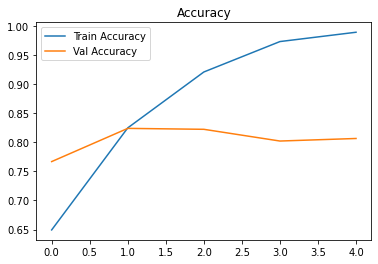

782/782 ━━━━━━━━━━━━━━━━━━━━ 48s 61ms/step


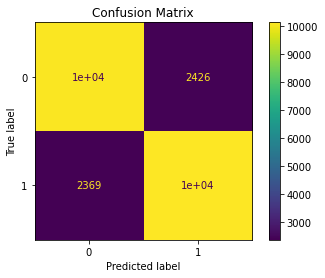

In [7]:
# Accuracy Graph
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend(); plt.title('Accuracy'); plt.show()

# Confusion Matrix
y_pred = (model.predict(x_test) > 0.5).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()
plt.title('Confusion Matrix'); plt.show()
